In [51]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score




from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor



In [24]:
df = pd.read_csv("../Data/processed/smartphones_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (1020, 31)
                      model  \
0              OPPO F35 Pro   
1  Samsung Galaxy S25 Ultra   
2             OPPO K14 Plus   
3   Motorola Edge 70 Fusion   
4               Vivo V80 5G   

                                                 url     brand scrape_date  \
0                             https://smpx.to/jifOik      OPPO  2026-10-14   
1  https://www.smartprix.com/mobiles/samsung-gala...   Samsung  2026-10-14   
2  https://www.smartprix.com/mobiles/oppo-k14-plu...      OPPO  2026-10-14   
3  https://www.smartprix.com/mobiles/motorola-edg...  Motorola  2026-10-14   
4  https://www.smartprix.com/mobiles/vivo-v80-5g-...      Vivo  2026-10-14   

   price_inr  spec_score                 processor_name  cpu_cores  cpu_ghz  \
0      45999          80             Dimensity 7360 Max        8.0     2.50   
1      94999          92  Snapdragon 8 Elite for Galaxy        8.0     4.47   
2      25999          75             Dimensity 7360 Max        8.0     2.50   
3 

In [25]:
# Select only the records intended for the primary analysis
ml_df = df.loc[df["in_analysis_scope"] == True].copy()

# Define the target
target = "price_inr"

print("ML dataset shape:", ml_df.shape)
print("Missing target values:", ml_df[target].isna().sum())
print("Target price summary:")
print(ml_df[target].describe())

ML dataset shape: (838, 31)
Missing target values: 0
Target price summary:
count       838.000000
mean      44113.464200
std       46450.424966
min        6499.000000
25%       18999.000000
50%       29999.000000
75%       49990.000000
max      449900.000000
Name: price_inr, dtype: float64


In [26]:
# Target: smartphone listed price in INR
ml_df["price_inr"] = pd.to_numeric(ml_df["price_inr"], errors="coerce")
print("ML rows:", len(ml_df))
print("Missing prices:", ml_df["price_inr"].isna().sum())
print(ml_df["price_inr"].describe())

assert ml_df["price_inr"].notna().all()

ML rows: 838
Missing prices: 0
count       838.000000
mean      44113.464200
std       46450.424966
min        6499.000000
25%       18999.000000
50%       29999.000000
75%       49990.000000
max      449900.000000
Name: price_inr, dtype: float64


In [27]:
# Numeric predictors
numeric_features = [
    "spec_score",
    "ram_gb",
    "storage_gb",
    "cpu_cores",
    "cpu_ghz",
    "battery_mah",
    "fast_charge_w",
    "screen_in",
    "res_short",
    "res_long",
    "refresh_hz",
    "rear_main_mp",
    "rear_mp_value_count",
    "front_mp",
    "os_major"
]

# Categorical predictors
categorical_features = [
    "brand",
    "processor_name",
    "os_family",
    "charging_status",
    "is_foldable",
    "is_5g",
    "has_nfc",
    "has_esim",
    "has_memory_card"
]




In [28]:
# Select features
features = numeric_features + categorical_features

X = ml_df[features].copy()
y = ml_df["price_inr"].copy()

print("X shape:", X.shape)
print("Features:", len(features))

X shape: (838, 24)
Features: 24


In [29]:
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(features))

Numeric features: 15
Categorical features: 9
Total features: 24


In [30]:

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 670
Testing rows: 168


In [44]:
#  Preprocess numeric and categorical features separately
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("string_converter", FunctionTransformer(
        lambda X: X.astype(str),
        feature_names_out="one-to-one"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features) ,
    
] ,  sparse_threshold=0)

In [32]:

# 4. Baseline ML model: Linear Regression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Predict prices for unseen test data
predictions = model.predict(X_test)

# Evaluate the baseline model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("BASELINE MODEL: LINEAR REGRESSION")
print("-" * 40)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", len(features))
print()
print(f"MAE:  ₹{mae:,.2f}")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"R²:   {r2:.4f}")


BASELINE MODEL: LINEAR REGRESSION
----------------------------------------
Training rows: 670
Testing rows: 168
Features: 24

MAE:  ₹6,818.77
RMSE: ₹10,651.11
R²:   0.9600


In [33]:

# 5. Dummy baseline: predict the training-set mean

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)
dummy_predictions = dummy_model.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_r2 = r2_score(y_test, dummy_predictions)

print("DUMMY BASELINE")
print("-" * 40)
print(f"MAE: ₹{dummy_mae:,.2f}")
print(f"R²:  {dummy_r2:.4f}")


DUMMY BASELINE
----------------------------------------
MAE: ₹31,384.12
R²:  -0.0087


In [34]:

# 6. Five-fold cross-validation

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(model, X,y, cv=cv, scoring="r2", n_jobs=-1)

print("CROSS-VALIDATION RESULTS")
print("-" * 40)
print("Fold scores:", cv_scores.round(4))
print(f"Mean R²: {cv_scores.mean():.4f}")
print(f"Minimum R²: {cv_scores.min():.4f}")
print(f"Maximum R²: {cv_scores.max():.4f}")


CROSS-VALIDATION RESULTS
----------------------------------------
Fold scores: [0.96   0.9252 0.914  0.9327 0.9356]
Mean R²: 0.9335
Minimum R²: 0.9140
Maximum R²: 0.9600


In [35]:

# 7. Helper function for feature ablation

def evaluate_ablation(feature_to_remove):

    selected_features = [col for col in features
        if col != feature_to_remove]

    num_cols = [
        col for col in numeric_features
        if col in selected_features]

    cat_cols = [
        col for col in categorical_features
        if col in selected_features]

    ablation_preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, num_cols),
        ("categorical", categorical_pipeline, cat_cols)
    ])

    ablation_model = Pipeline([
        ("preprocessor", ablation_preprocessor),
        ("regressor", LinearRegression())
    ])

    scores = cross_val_score(
        ablation_model,
        X[selected_features],
        y,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    return scores


In [36]:

# 8. Compare both feature ablations

ablation_results = []

for feature_to_remove in ["spec_score", "os_major"]:

    ablated_scores = evaluate_ablation(feature_to_remove)

    # Compare matching folds
    differences = cv_scores - ablated_scores

    print(f"\nWithout {feature_to_remove}")
    print("Ablated scores:", ablated_scores.round(4))
    print("Base - ablated:", differences.round(4))
    print(f"Mean ablated R²: {ablated_scores.mean():.4f}")
    print(f"Mean difference: {differences.mean():.4f}")

    for fold, (base, ablated, diff) in enumerate(
        zip(cv_scores, ablated_scores, differences),
        start=1
    ):
        ablation_results.append({
            "Feature removed": feature_to_remove,
            "Fold": fold,
            "Base R²": base,
            "Ablated R²": ablated,
            "Base - ablated": diff
        })

ablation_df = pd.DataFrame(ablation_results)

print("\nPer-fold comparison:")
print(ablation_df.round(4).to_string(index=False))



Without spec_score
Ablated scores: [0.9566 0.9116 0.911  0.9218 0.934 ]
Base - ablated: [0.0035 0.0137 0.003  0.011  0.0016]
Mean ablated R²: 0.9270
Mean difference: 0.0065

Without os_major
Ablated scores: [0.9601 0.9255 0.9124 0.9327 0.9355]
Base - ablated: [-0.0001 -0.0003  0.0016 -0.      0.0001]
Mean ablated R²: 0.9333
Mean difference: 0.0003

Per-fold comparison:
Feature removed  Fold  Base R²  Ablated R²  Base - ablated
     spec_score     1   0.9600      0.9566          0.0035
     spec_score     2   0.9252      0.9116          0.0137
     spec_score     3   0.9140      0.9110          0.0030
     spec_score     4   0.9327      0.9218          0.0110
     spec_score     5   0.9356      0.9340          0.0016
       os_major     1   0.9600      0.9601         -0.0001
       os_major     2   0.9252      0.9255         -0.0003
       os_major     3   0.9140      0.9124          0.0016
       os_major     4   0.9327      0.9327         -0.0000
       os_major     5   0.9356      0


### I expect the log-price model may have a lower R² on the original price scale because it focuses more on proportional errors than large absolute errors. I expect MAPE to improve because it evaluates prediction errors relative to actual prices, although this is not guaranteed.###

In [37]:

# Evaluate models on the original price scale
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "mape": "neg_mean_absolute_percentage_error"
}

print("Metrics configured.")
print("R²: higher is better")
print("MAE: lower is better")
print("MAPE: lower is better")


Metrics configured.
R²: higher is better
MAE: lower is better
MAPE: lower is better


In [38]:

# Original price target
plain_results = cross_validate(clone(model), X, y, cv=cv, scoring=scoring, n_jobs=-1)

print("Original-price model evaluated.")
print(f"Mean CV R²: {plain_results['test_r2'].mean():.4f}")
print(f"Mean CV MAE: ₹{-plain_results['test_mae'].mean():,.2f}")
print(f"Mean CV MAPE: {-plain_results['test_mape'].mean() * 100:.2f}%")


Original-price model evaluated.
Mean CV R²: 0.9335
Mean CV MAE: ₹7,310.01
Mean CV MAPE: 21.41%


In [39]:

# Log-transformed target
log_model = TransformedTargetRegressor(
    regressor=clone(model),
    func=np.log1p,
    inverse_func=np.expm1
)

log_results = cross_validate(log_model, X,y, cv=cv,scoring=scoring, n_jobs=-1)

print("Log-price model evaluated.")
print(f"Mean CV R²: {log_results['test_r2'].mean():.4f}")
print(f"Mean CV MAE: ₹{-log_results['test_mae'].mean():,.2f}")
print(f"Mean CV MAPE: {-log_results['test_mape'].mean() * 100:.2f}%")


Log-price model evaluated.
Mean CV R²: 0.9263
Mean CV MAE: ₹6,231.93
Mean CV MAPE: 13.80%


In [40]:

comparison = pd.DataFrame([
    {
        "Model": "Original price",
        "Mean R²": plain_results["test_r2"].mean(),
        "Mean MAE (INR)": -plain_results["test_mae"].mean(),
        "Mean MAPE (%)": -plain_results["test_mape"].mean() * 100
    },
    {
        "Model": "Log price",
        "Mean R²": log_results["test_r2"].mean(),
        "Mean MAE (INR)": -log_results["test_mae"].mean(),
        "Mean MAPE (%)": -log_results["test_mape"].mean() * 100
    }
])

print(comparison.round(4).to_string(index=False))

print("\nFold-by-fold R²:")
print(pd.DataFrame({
    "Fold": range(1, len(plain_results["test_r2"]) + 1),
    "Original price": plain_results["test_r2"],
    "Log price": log_results["test_r2"]
}).round(4).to_string(index=False))


         Model  Mean R²  Mean MAE (INR)  Mean MAPE (%)
Original price   0.9335       7310.0120        21.4140
     Log price   0.9263       6231.9254        13.8039

Fold-by-fold R²:
 Fold  Original price  Log price
    1          0.9600     0.9552
    2          0.9252     0.9419
    3          0.9140     0.8991
    4          0.9327     0.8987
    5          0.9356     0.9369


**My prediction before model comparison**

I expect Random Forest or HistGradientBoostingRegressor to achieve the lowest MAPE because tree-based models can capture nonlinear relationships between smartphone specifications and prices. I expect Random Forest to have less stable fold scores because its predictions can vary with the sampled training data and the small number of premium phones.

### Ridge
- alpha=1.0: a moderate starting regularization strength. It penalizes large coefficients and can reduce overfitting.
- We will tune alpha only if Ridge wins the initial comparison.
  
###  Random Forest
- n_estimators=300: enough trees for a reasonably stable starting estimate without excessive training time.
- min_samples_leaf=2: prevents leaves containing just one training observation, providing mild regularization.
- random_state=42: makes the experiment reproducible.
  
###  HistGradientBoosting
- max_iter=200: trains up to 200 boosting iterations.
- learning_rate=0.05: uses relatively small boosting steps to reduce aggressive fitting.
- max_leaf_nodes=15: limits each tree's complexity, useful for a dataset of roughly 838 in-scope phones.
  
###  XGBoost
- n_estimators=300: caps the number of boosting trees.
- learning_rate=0.05: makes each tree's contribution more conservative.
- max_depth=4: limits interaction complexity.
- subsample=0.8: uses 80% of training rows per boosting iteration.
- colsample_bytree=0.8: samples 80% of features per tree.
- reg_lambda=5: adds L2 regularization to discourage overly complex fits.
  XGBoost documentation explains that learning rate controls shrinkage and deeper trees increase complexity and overfitting risk. 
  
  
###  LightGBM
- n_estimators=300: caps the number of boosting iterations.
- learning_rate=0.05: conservative learning steps.
- num_leaves=15: restricts the number of terminal leaves per tree.
- max_depth=6: caps depth to help control complexity.
- min_child_samples=20: requires a reasonable number of observations in a leaf.
- reg_lambda=5: adds L2 regularization.

In [41]:
# Create a reusable pipeline with log-transformed target

def make_log_model(estimator):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("regressor", estimator)
        ]),
        func=np.log1p,
        inverse_func=np.expm1
    )

In [42]:

candidate_models = {
    "Ridge": Ridge(
        alpha=1.0
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=6,
        min_child_samples=20,
        reg_lambda=5,
        verbosity=-1,
        random_state=42,
        n_jobs=1
    )
}


In [45]:

results = []

for name, estimator in candidate_models.items():
    candidate = make_log_model(clone(estimator))

    scores = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "Std R2": scores["test_r2"].std(ddof=1),
        "Mean MAE (INR)": -scores["test_mae"].mean(),
        "Mean MAPE (%)": -scores["test_mape"].mean() * 100
    })

comparison = (
    pd.DataFrame(results)
    .sort_values("Mean MAPE (%)")
    .reset_index(drop=True)
)

print(comparison.round(4).to_string(index=False))


                 Model  Mean R2  Std R2  Mean MAE (INR)  Mean MAPE (%)
                 Ridge   0.8857  0.0564       6287.3711        12.9870
               XGBoost   0.8648  0.1258       6546.3253        13.2875
              LightGBM   0.8530  0.1180       6876.5781        13.6011
Hist Gradient Boosting   0.8519  0.1033       6980.9220        13.9372
         Random Forest   0.8460  0.1295       7282.3775        14.5799


## Final Model Selection: Ridge vs. XGBoost

### Why compare these two models?

The initial five-fold cross-validation results identified Ridge as the strongest candidate, achieving a mean MAPE of 12.99% and a mean R² of 0.8857. XGBoost was the closest competitor on prediction error, with a mean MAPE of 13.29% and a mean R² of 0.8648.

I selected these two models for final hyperparameter tuning because they represent different modelling approaches:

- **Ridge Regression:** A regularized linear model that controls coefficient magnitude and provides a relatively simple, interpretable baseline.
- **XGBoost:** A gradient-boosted tree model that can capture nonlinear relationships and interactions between smartphone specifications.

Ridge currently has better average metrics and more stable fold scores. However, XGBoost may improve after tuning, so the initial results alone are not sufficient to make the final decision.

### Tuning strategy

Both models will use the same preprocessing pipeline, log-transformed price target, five-fold cross-validation, and training data. Hyperparameters will be selected using MAPE, which measures prediction error relative to the actual phone price.

For Ridge, I will tune the regularization parameter `alpha`. For XGBoost, I will tune the number of trees, learning rate, tree depth, row sampling, feature sampling, and L2 regularization.

The final comparison will consider mean MAPE, mean MAE, mean R², and fold-to-fold stability. I will select the final model using cross-validation results and evaluate it once on the untouched test set.


In [46]:

# Final tuning: Ridge Regression

from sklearn.model_selection import GridSearchCV

ridge_pipeline = make_log_model(Ridge())

ridge_param_grid = {
    "regressor__regressor__alpha": np.logspace(-3, 3, 13)
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring=scoring,
    refit="mape",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge parameters:", ridge_search.best_params_)
print(f"Best CV MAPE: {-ridge_search.best_score_ * 100:.2f}%")


Best Ridge parameters: {'regressor__regressor__alpha': np.float64(1.0)}
Best CV MAPE: 12.99%


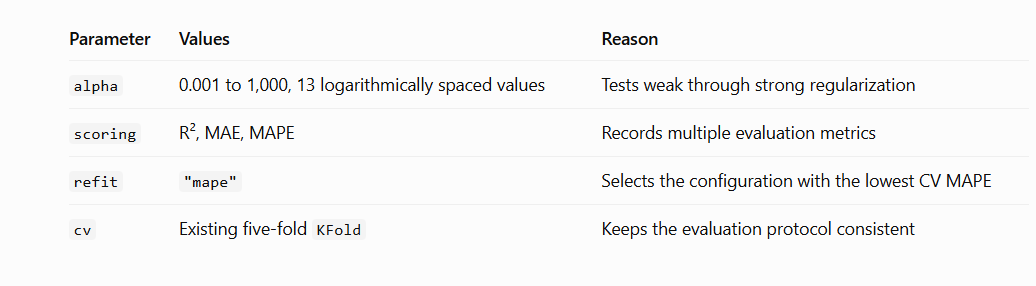

In [47]:

# Final tuning: XGBoost

xgb_pipeline = make_log_model(
    clone(candidate_models["XGBoost"])
)

xgb_param_grid = {
    "regressor__regressor__n_estimators": [200, 400],
    "regressor__regressor__learning_rate": [0.03, 0.05],
    "regressor__regressor__max_depth": [2, 3, 4],
    "regressor__regressor__subsample": [0.8, 1.0],
    "regressor__regressor__colsample_bytree": [0.8, 1.0],
    "regressor__regressor__reg_lambda": [1, 5]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring=scoring,
    refit="mape",
    cv=cv,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost parameters:", xgb_search.best_params_)
print(f"Best CV MAPE: {-xgb_search.best_score_ * 100:.2f}%")


Best XGBoost parameters: {'regressor__regressor__colsample_bytree': 0.8, 'regressor__regressor__learning_rate': 0.05, 'regressor__regressor__max_depth': 4, 'regressor__regressor__n_estimators': 400, 'regressor__regressor__reg_lambda': 1, 'regressor__regressor__subsample': 0.8}
Best CV MAPE: 12.57%


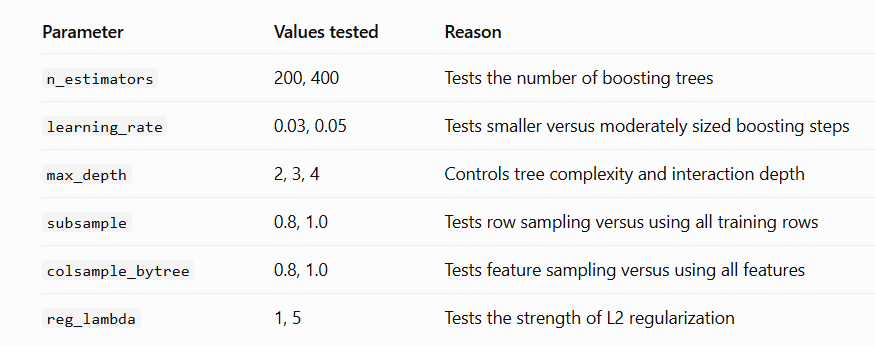

In [48]:

# Final cross-validation comparison after tuning

searches = {
    "Ridge (tuned)": ridge_search,
    "XGBoost (tuned)": xgb_search
}

tuned_results = []

for name, search in searches.items():
    idx = search.best_index_
    cv_results = search.cv_results_

    tuned_results.append({
        "Model": name,
        "Mean R2": cv_results["mean_test_r2"][idx],
        "Std R2": cv_results["std_test_r2"][idx],
        "Mean MAE (INR)": -cv_results["mean_test_mae"][idx],
        "Mean MAPE (%)": -cv_results["mean_test_mape"][idx] * 100
    })

tuned_comparison = (
    pd.DataFrame(tuned_results)
    .sort_values("Mean MAPE (%)")
    .reset_index(drop=True)
)

print(tuned_comparison.round(4).to_string(index=False))


          Model  Mean R2  Std R2  Mean MAE (INR)  Mean MAPE (%)
XGBoost (tuned)   0.8727  0.1090       6272.1837        12.5722
  Ridge (tuned)   0.8857  0.0504       6287.3711        12.9870


### What do these results tell us?

- **MAPE:** XGBoost reduces the average percentage error by approximately 0.415 percentage points compared with Ridge.
- **MAE:** XGBoost reduces the average absolute error by approximately ₹15 per phone. This is a very small improvement.
- **R²:** Ridge explains more variation in the target on average.
- **Stability:** Ridge's standard deviation of fold R² is less than half that of XGBoost. Its performance is more consistent across the five folds.

The evidence is mixed: XGBoost has a small advantage in prediction error, while Ridge is more stable.

### Interpretation of the Tuned Model Comparison

After hyperparameter tuning, XGBoost achieved a mean MAPE of 12.57%, compared with 12.99% for Ridge. However, its mean MAE improved by only approximately ₹15 per phone.

Ridge achieved a higher mean R² of 0.8857 and a lower standard deviation of fold R² of 0.0504, compared with 0.8727 and 0.1090 for XGBoost. This indicates that Ridge provides more consistent performance across the cross-validation folds.

The results present a trade-off between minimizing relative prediction error and maintaining model stability. XGBoost currently leads on MAPE, but its advantage is modest. I will inspect the fold-level results and evaluate both tuned models using the same untouched test set before selecting the final model.

In [52]:

# Final evaluation: selected XGBoost model

final_model = xgb_search.best_estimator_

# Evaluate once on the untouched test set
test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)
test_mape = mean_absolute_percentage_error(
    y_test, test_predictions
) * 100

print("FINAL MODEL: TUNED XGBOOST")
print("-" * 40)
print("Best parameters:", xgb_search.best_params_)
print(f"Test R²:   {test_r2:.4f}")
print(f"Test MAE:  ₹{test_mae:,.2f}")
print(f"Test RMSE: ₹{test_rmse:,.2f}")
print(f"Test MAPE: {test_mape:.2f}%")


FINAL MODEL: TUNED XGBOOST
----------------------------------------
Best parameters: {'regressor__regressor__colsample_bytree': 0.8, 'regressor__regressor__learning_rate': 0.05, 'regressor__regressor__max_depth': 4, 'regressor__regressor__n_estimators': 400, 'regressor__regressor__reg_lambda': 1, 'regressor__regressor__subsample': 0.8}
Test R²:   0.9786
Test MAE:  ₹4,723.27
Test RMSE: ₹7,787.46
Test MAPE: 10.42%


In [ ]:
# Calculate prediction errors
# Error analysis: individual test predictions

error_df = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": test_predictions
})

# Residual = actual - predicted
error_df["residual"] = (
    error_df["actual_price"] - error_df["predicted_price"]
)

error_df["absolute_error"] = error_df["residual"].abs()

error_df["absolute_percentage_error"] = (
    error_df["absolute_error"] / error_df["actual_price"] * 100
)

print("Test prediction error summary:")
print(
    error_df[
        ["actual_price", "predicted_price", "residual",
         "absolute_error", "absolute_percentage_error"]
    ].head(10).round(2).to_string(index=False)
)

print("\nLargest prediction errors:")
print(
    error_df.nlargest(10, "absolute_error")[
        ["actual_price", "predicted_price", "residual", "absolute_error"]
    ].round(2).to_string(index=False)
)




Test prediction error summary:
 actual_price  predicted_price  residual  absolute_error  absolute_percentage_error
        32149     33626.398438  -1477.41         1477.41                       4.60
        31999     27337.990234   4661.01         4661.01                      14.57
        31470     33003.429688  -1533.43         1533.43                       4.87
        14999     16035.209961  -1036.21         1036.21                       6.91
        12249     13070.200195   -821.20          821.20                       6.70
        28990     19189.660156   9800.34         9800.34                      33.81
        17999     25337.220703  -7338.21         7338.21                      40.77
        22499     21746.730469    752.27          752.27                       3.34
        32499     34140.781250  -1641.79         1641.79                       5.05
        64999     62020.261719   2978.74         2978.74                       4.58

Largest prediction errors:
 actual_price  pr

In [54]:
# Evaluate performance by price segment

# Error analysis by actual price segment

error_df["price_segment"] = pd.cut(
    error_df["actual_price"],
    bins=[0, 10000, 25000, 50000, float("inf")],
    labels=["Budget (≤₹10k)", "Mid (₹10k–25k)",
            "Upper-mid (₹25k–50k)", "Premium (>₹50k)"],
    include_lowest=True
)

segment_results = (
    error_df.groupby("price_segment", observed=False)
    .agg(
        phones=("actual_price", "count"),
        median_actual_price=("actual_price", "median"),
        MAE=("absolute_error", "mean"),
        MAPE=("absolute_percentage_error", "mean")
    )
    .reset_index()
)

print(segment_results.round(2).to_string(index=False))


       price_segment  phones  median_actual_price      MAE  MAPE
      Budget (≤₹10k)      10               9444.5   796.35  8.95
      Mid (₹10k–25k)      53              17442.0  2172.59 12.29
Upper-mid (₹25k–50k)      64              34494.5  3352.48  9.47
     Premium (>₹50k)      41              89999.0 11118.05  9.85


# Final Model Selection and Error Analysis

## Model selection

I compared tuned Ridge Regression and XGBoost using five-fold cross-validation on the training data. XGBoost achieved a lower mean MAPE of 12.57%, compared with 12.99% for Ridge, and a slightly lower mean MAE (₹6,272 vs. ₹6,287). Ridge had a higher mean R² and more stable fold scores. I selected XGBoost because minimizing relative prediction error was the primary objective.

## Final test performance

On the held-out test set, XGBoost achieved an R² of 0.9786, MAE of ₹4,723.27, RMSE of ₹7,787.46, and MAPE of 10.42%.

## Error analysis by price segment

The mid-range segment (₹10,000–₹25,000) had the highest MAPE at 12.29%. Premium phones had the highest absolute MAE at ₹11,118.05, but their MAPE was 9.85%. The budget segment had the lowest MAPE at 8.95%, although it contained only 10 test records, so this result should be interpreted cautiously.

## Limitation

The test R² is higher than the cross-validation average, so the test result may reflect an easier sample. The model predicts prices recorded on Smartprix at collection time, which may differ from current retail prices, particularly for older or discontinued phones.